# Validate linear summation (metamodel vs dynamic)

Compare offshore-driven **dynamic SnapWave** to the **reconstructed metamodel**
(spectral mode: WHACS partitions `0`–`3` per goal, wavespectra linear sum).

Bulk output is configured in the case JSON → `metamodel.reconstruction.variables`
(HyGloW name → wavespectra stat). Set `save_spectra: true` to cache summed spectra
for notebook 11.

Comparison uses `hs`, `tp`, `dir`, and `spr` when both datasets contain them
(`val.resolve_comparison_variables`).

**Prerequisites:** fitted models (06), dynamic run (08). Use `recompute=True` after refitting.

In [1]:
import time

import matplotlib.pyplot as plt
import xarray as xr
from utils.config import SIMULATIONS, resolve
from utils.evaluation import validation as val
from utils.model import metamodel as mm

## Configuration

In [2]:
period = "2010-01"
offshore_name = "WHACS"
mda_n = 450  # must match a fitted mda_candidates entry
pca_variance = 0.99  # or 0.99, or {"hs": 0.99, etc}

# Site subset — isobath depth, mesh polygon, buoy id, or umbrella
sites = None  # e.g. "10m", "buoy", or a list of explicit site ids

# Metrics to compare (subset used when missing from either dataset)
compare_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_2010.nc"
)

print(f"period       : {period}")
print(f"mda_n        : {mda_n}")
print(f"sites        : {sites}")
print(f"compare vars : {compare_variables}")
print(f"dynamic path : {dynamic_path}")

period       : 2010-01
mda_n        : 450
sites        : None
compare vars : ['hs', 'tp', 'dir', 'spr']
dynamic path : /hyglowdata/NewSouthWales/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_2010.nc


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)
print(f"common model sites: {len(mm.common_model_sites())}")

common model sites: 3860


## 2 · Reconstruct metamodel (bulk)

In [4]:
t0 = time.perf_counter()
metamodel = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
    workers=4,
    save_spectra=False,  # bulk-vs-dynamic validation never reads spectra —
    # the case JSON defaults save_spectra=true (for notebook 11), which was
    # needlessly computing and accumulating a full (time, sites, freq, dir)
    # array per batch here, ~1000x bigger than the bulk stats actually
    # used below, and was the real driver of the memory growth observed
    # running this at the full 3,860-site scale.
)
reconstruct_seconds = time.perf_counter() - t0
print(
    f"Reconstruction took {reconstruct_seconds:.2f}s for {metamodel.sizes.get('sites', '?')} sites"
)
metamodel

Reconstruction took 2.23s for 3860 sites


<xarray.Dataset> Size: 81MB
Dimensions:         (time: 744, sites: 3860)
Coordinates:
  * time            (time) datetime64[ns] 6kB 2010-01-01 ... 2010-01-31T23:00:00
  * sites           (sites) <U22 340kB '20m_793' '20m_794' ... '20m_792'
    site_source     (sites) <U7 108kB 'isobath' 'isobath' ... 'isobath'
    site_label      (sites) <U5 77kB '20m' '20m' '20m' ... '20m' '20m' '20m'
    site_depth      (sites) float64 31kB -20.0 -20.0 -20.0 ... -20.0 -20.0 -20.0
    site_longitude  (sites) float64 31kB 152.8 152.8 152.8 ... 152.8 152.8 152.8
    site_latitude   (sites) float64 31kB -31.81 -31.82 -31.82 ... -31.81 -31.82
Data variables:
    hs              (time, sites) float64 23MB 1.336 1.336 1.332 ... 1.722 1.735
    tp              (time, sites) float32 11MB 6.193 6.194 6.194 ... 7.929 7.937
    dir             (time, sites) float64 23MB 63.75 63.8 63.82 ... 83.91 81.58
    spr             (time, sites) float64 23MB 29.81 29.9 29.31 ... 29.36 29.62

## 3 · Load dynamic reference

In [5]:
dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()
dynamic

<xarray.Dataset> Size: 47MB
Dimensions:         (time: 744, sites: 3860)
Coordinates:
  * time            (time) datetime64[ns] 6kB 2010-01-01 ... 2010-01-31T23:00:00
  * sites           (sites) <U22 340kB '10m_100' ... 'buoy_Worimi_Buoy'
    site_source     (sites) <U7 108kB 'isobath' 'isobath' ... 'buoy' 'buoy'
    site_label      (sites) <U5 77kB '10m' '10m' '10m' ... 'waves' 'waves'
    site_depth      (sites) float64 31kB -10.0 -10.0 -10.0 ... -13.62 -13.62
    site_longitude  (sites) float64 31kB 153.0 153.0 152.9 ... 151.4 150.9 151.8
    site_latitude   (sites) float64 31kB -31.31 -31.35 -31.39 ... -34.35 -32.88
Data variables:
    hs              (time, sites) float32 11MB 1.231 1.185 1.147 ... 1.224 1.227
    tp              (time, sites) float32 11MB 6.474 6.474 6.474 ... 7.766 7.766
    dir             (time, sites) float32 11MB 71.18 79.69 81.26 ... 83.77 110.1
    spr             (time, sites) float32 11MB 25.85 36.28 31.67 ... 19.64 23.59
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

## 4 · Compare

In [6]:
variables = val.resolve_comparison_variables(
    metamodel,
    dynamic,
    variables=compare_variables,
)
print(f"Comparing: {variables}")

result = val.compare(
    metamodel,
    dynamic,
    variables=variables,
    estimate_label="Linear summation",
    reference_label="Dynamic SnapWave",
    pca_variance=pca_variance,
)
result.metrics

Comparing: ['hs', 'tp', 'dir', 'spr']


,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,hs,Hs,933720,0.070228,0.227339,0.814930,Linear summation,Dynamic SnapWave
1,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,tp,Tp,932421,-0.015153,1.408971,0.485586,Linear summation,Dynamic SnapWave
2,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,dir,Dir,933720,0.933980,29.828930,0.417539,Linear summation,Dynamic SnapWave
3,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",5m,isobath,5m,spr,Spr,932355,-0.205300,7.231065,0.298223,Linear summation,Dynamic SnapWave
4,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,hs,Hs,691176,0.047888,0.185355,0.835173,Linear summation,Dynamic SnapWave
...,...,...,...,...,...,...,...,...,...,...,...,...
151,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Woonona_Buoy,buoy,waves,spr,Spr,744,3.230109,6.755769,-0.631746,Linear summation,Dynamic SnapWave
152,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Worimi_Buoy,buoy,waves,hs,Hs,744,0.175499,0.236989,0.771164,Linear summation,Dynamic SnapWave
153,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Worimi_Buoy,buoy,waves,tp,Tp,744,-0.026578,1.200767,0.609747,Linear summation,Dynamic SnapWave
154,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Worimi_Buoy,buoy,waves,dir,Dir,744,1.488597,16.264665,0.552837,Linear summation,Dynamic SnapWave


## 5 · Save metrics

In [7]:
metrics_out = result.metrics.copy()
metrics_out.insert(0, "period", period)
metrics_out.insert(1, "mda_candidate", mda_n)
metrics_out.insert(2, "offshore_name", offshore_name)
metrics_out["n_sites"] = int(metamodel.sizes["sites"])
# Wall time for mm.reconstruct() above — near-zero if these sites/period
# were already cached from a previous run, not a fresh-simulation cost.
metrics_out["reconstruct_seconds"] = reconstruct_seconds

out_path = val.metamodel_validation_path(period)
out_path.parent.mkdir(parents=True, exist_ok=True)
metrics_out.to_csv(out_path, index=False)
print(f"Wrote {out_path}")

Wrote /home/tausiaj/GitHub-GeoOcean/HyGloW/NewSouthWales/outputs/metamodel_validation/linear_summation_2010-01.csv


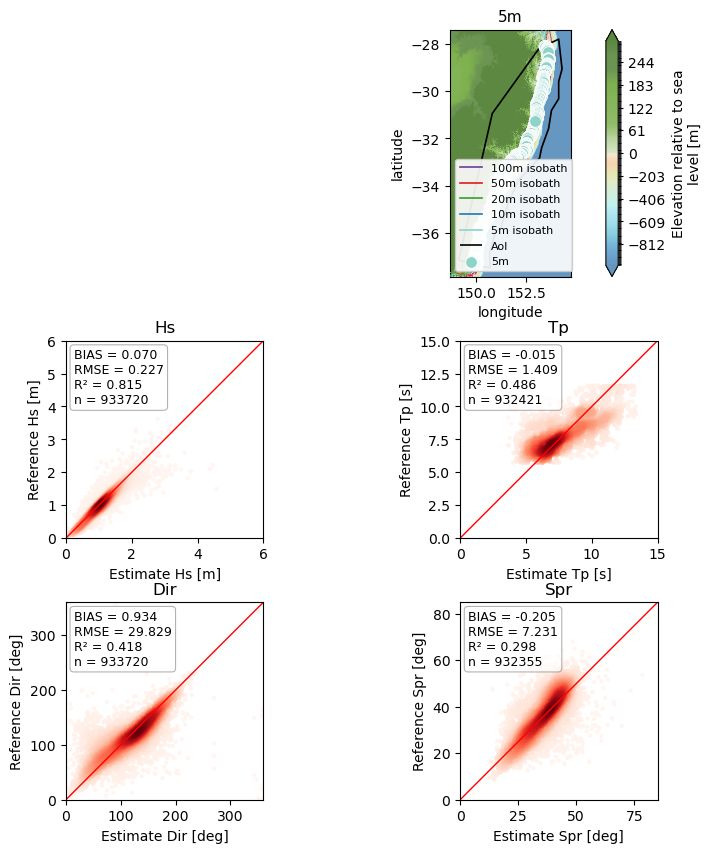

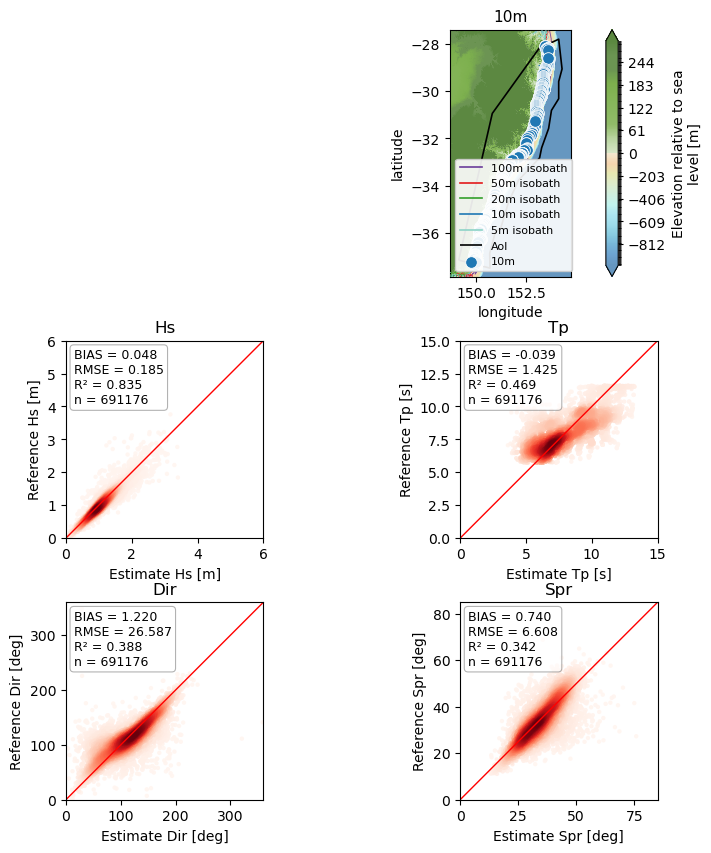

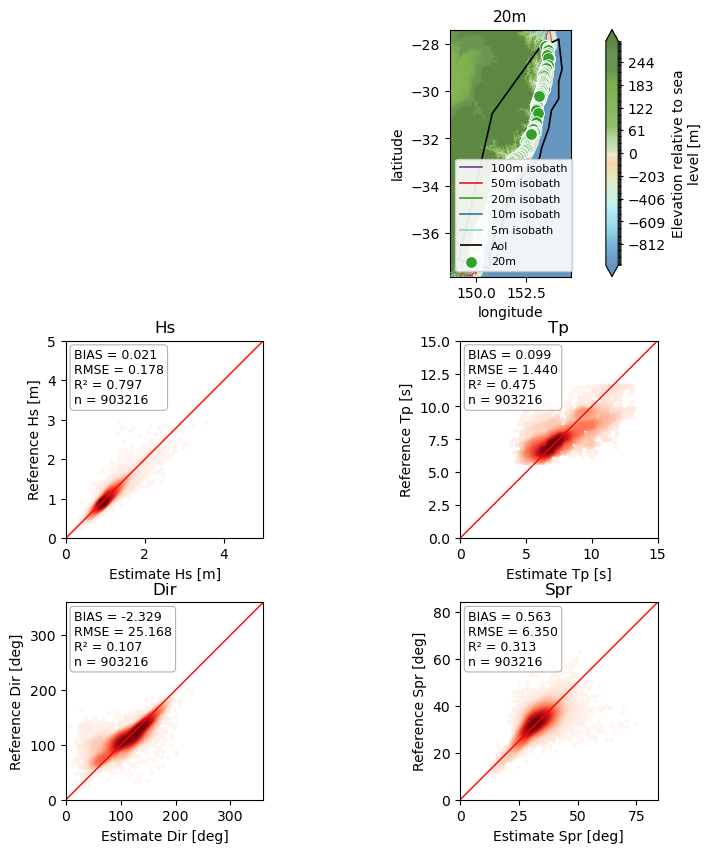

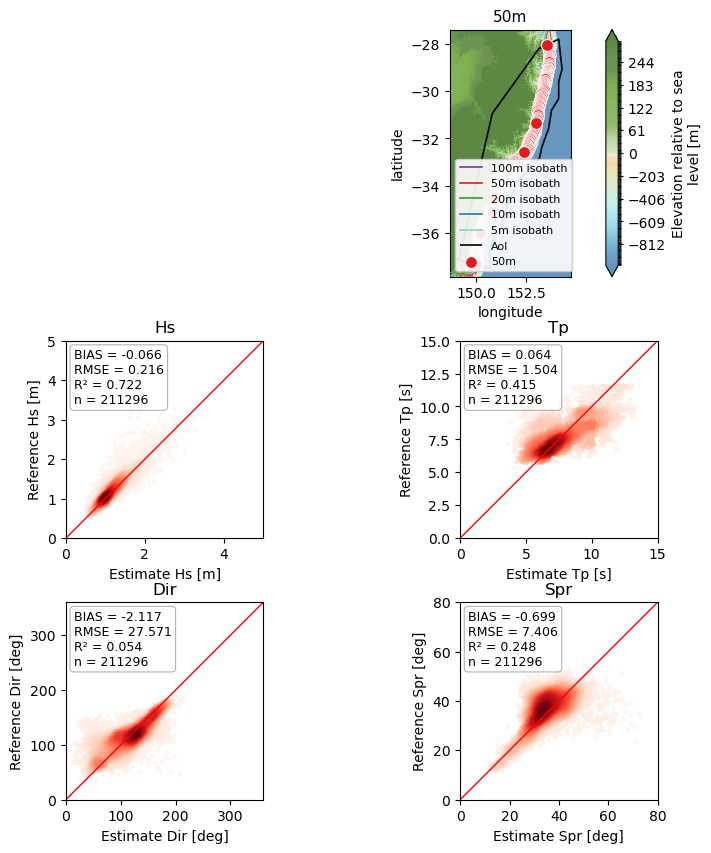

In [11]:
result.plot_all(variables=variables, cmap="Reds", groups=["5m", "10m", "20m", "50m"])
plt.show()